In [1]:
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.svm import SVC
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier, VotingClassifier

from sklearn.model_selection import cross_val_score
from sklearn.datasets import make_classification

In [2]:
df = sns.load_dataset('iris')

In [3]:
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [4]:
encoder = LabelEncoder()

df['species'] = encoder.fit_transform(df['species'])

In [5]:
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


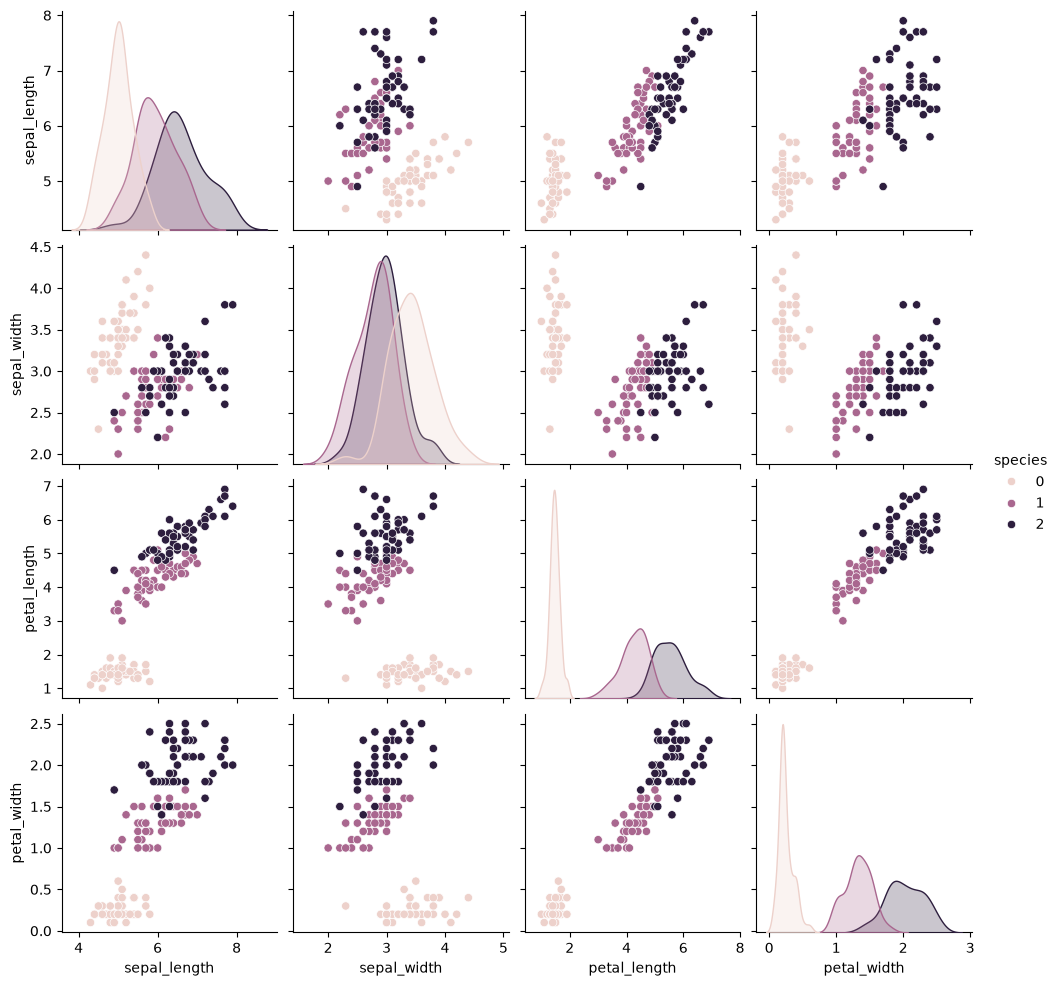

In [6]:
sns.pairplot(df,hue='species')

In [7]:
new_df = df[df['species'] != 0][['sepal_length','sepal_width','species']]

In [8]:
new_df.head()

,sepal_length,sepal_width,species
50,7.0,3.2,1
51,6.4,3.2,1
52,6.9,3.1,1
53,5.5,2.3,1
54,6.5,2.8,1


In [9]:
new_df.shape

(100, 3)

In [10]:
X = df.iloc[:,0:2]
y = df.iloc[:,-1]

In [11]:
clf1 = LogisticRegression()
clf2 = RandomForestClassifier()
clf3 = KNeighborsClassifier()

In [12]:
estimators = [('lr',clf1),('rf',clf2),('knn',clf3)]

In [13]:
for estimator in estimators:
    x = cross_val_score(estimator[1],X,y,cv=10,scoring='accuracy')
    print(estimator[0],np.round(np.mean(x),2))

lr 0.81
rf 0.72
knn 0.76


## Hard Voting:

In [14]:
vc = VotingClassifier(estimators=estimators,voting='hard')
x = cross_val_score(vc,X,y,cv=10,scoring='accuracy')
print(np.round(np.mean(x),2))

0.77


## Soft Voting:

In [15]:
vc1 = VotingClassifier(estimators=estimators,voting='soft')
x = cross_val_score(vc1,X,y,cv=10,scoring='accuracy')
print(np.round(np.mean(x),2))

0.77


## Weighted Voting:

In [16]:
for i in range(1,4):
    for j in range(1,4):
        for k in range(1,4):
            vc = VotingClassifier(estimators=estimators,voting='soft',weights=[i,j,k])
            x = cross_val_score(vc,X,y,cv=10,scoring='accuracy')
            print("for i={},j={},k={}".format(i,j,k),np.round(np.mean(x),2))
            

for i=1,j=1,k=1 0.78
for i=1,j=1,k=2 0.77
for i=1,j=1,k=3 0.77
for i=1,j=2,k=1 0.75
for i=1,j=2,k=2 0.76
for i=1,j=2,k=3 0.76
for i=1,j=3,k=1 0.75
for i=1,j=3,k=2 0.76
for i=1,j=3,k=3 0.77
for i=2,j=1,k=1 0.77
for i=2,j=1,k=2 0.77
for i=2,j=1,k=3 0.77
for i=2,j=2,k=1 0.76
for i=2,j=2,k=2 0.76
for i=2,j=2,k=3 0.76
for i=2,j=3,k=1 0.76
for i=2,j=3,k=2 0.75
for i=2,j=3,k=3 0.76
for i=3,j=1,k=1 0.8
for i=3,j=1,k=2 0.78
for i=3,j=1,k=3 0.79
for i=3,j=2,k=1 0.78
for i=3,j=2,k=2 0.76
for i=3,j=2,k=3 0.76
for i=3,j=3,k=1 0.75
for i=3,j=3,k=2 0.77
for i=3,j=3,k=3 0.77


## Classifiers of Same Algorithm:

In [17]:
X, y = make_classification(n_samples=1000, n_features=20, n_informative=15, n_redundant=5, random_state=2)

estimators = [
    ('svm1', SVC(kernel='poly', degree=1)),
    ('svm2', SVC(kernel='poly', degree=2)),
    ('svm3', SVC(kernel='poly', degree=3)),
    ('svm4', SVC(kernel='poly', degree=4)),
    ('svm5', SVC(kernel='poly', degree=5))
]

for name, model in estimators:
    scores = cross_val_score(model, X, y, cv=10, scoring='accuracy')
    print(name, np.round(np.mean(scores), 2))

svm1 0.85
svm2 0.85
svm3 0.89
svm4 0.81
svm5 0.86


In [18]:
X, y = make_classification(n_samples=1000, n_features=20, n_informative=15, n_redundant=5, random_state=2)

estimators = [
    ('svm1', CalibratedClassifierCV(SVC(kernel='poly', degree=1), ensemble=False)),
    ('svm2', CalibratedClassifierCV(SVC(kernel='poly', degree=2), ensemble=False)),
    ('svm3', CalibratedClassifierCV(SVC(kernel='poly', degree=3), ensemble=False)),
    ('svm4', CalibratedClassifierCV(SVC(kernel='poly', degree=4), ensemble=False)),
    ('svm5', CalibratedClassifierCV(SVC(kernel='poly', degree=5), ensemble=False))
]

vc1 = VotingClassifier(estimators=estimators, voting='soft')
x = cross_val_score(vc1, X, y, cv=10, scoring='accuracy')

print(np.round(np.mean(x), 2))

0.93
